# 01 · Data preparation — *Will this transfer fail?*

**Project:** transfer-risk model for a sporting director (Lab 2, "AI Football Intelligence").

**Decision we support.** A club is about to pay for a player. Before signing, the director wants
the probability that the player ends up a **squad flop**, i.e. plays very little in his first season
at the new club, so the money is wasted. The notebooks answer: *can a model built only from
information available **before** the transfer rank risky deals better than simple rules of thumb?*

**This notebook** turns 5 raw Transfermarkt tables into one clean table:
**one row = one permanent summer transfer**, with
- `X` — features known **before** the transfer date,
- `y` — outcomes observed **after** it (never used as features).

| Step | What happens |
|---|---|
| 1 | Download data (pinned to a fixed commit → reproducible) |
| 2 | Audit: sizes, duplicates, bad dates, missing values |
| 3 | Build team-season and player-season tables |
| 4 | Select the transfer population (with a funnel table) |
| 5 | Define the target (`y_flop`) |
| 6 | Build pre-transfer features, with explicit leakage guards |
| 7 | Sanity checks, save `data/processed/transfers_model.csv.gz` |
| 8 | Limitations found (feeds the "pitfalls" part of the project) |

## 1 · Setup and data download

In [1]:
import os, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# Source: https://github.com/salimt/football-datasets (Transfermarkt scrape).
# We pin an exact commit so every teammate gets identical data.
COMMIT = "da9227e1f42baf74561324290dbf1ad2e3c00edd"
BASE_RAW = f"https://raw.githubusercontent.com/salimt/football-datasets/{COMMIT}/datalake/transfermarkt"
# Two big files are stored with Git LFS: raw.githubusercontent.com would return a tiny pointer
# file instead of the data, so they must come from the "media" host.
BASE_LFS = f"https://media.githubusercontent.com/media/salimt/football-datasets/{COMMIT}/datalake/transfermarkt"

# Works from the repo root, from notebooks/, and in Colab (cwd = /content): data always lands in <root>/data/
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
RAW_DIR, PROC_DIR = f"{ROOT}/data/raw", f"{ROOT}/data/processed"
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROC_DIR, exist_ok=True)

# name -> (folder/file on GitHub, uses LFS?)
SOURCES = {
    "transfers":    ("transfer_history/transfer_history",                      True),
    "performances": ("player_performances/player_performances",                True),
    "profiles":     ("player_profiles/player_profiles",                        False),
    "market_value": ("player_market_value/player_market_value",                False),
    "injuries":     ("player_injuries/player_injuries_updated_20260929",       False),
    "team_seasons": ("team_competitions_seasons/team_competitions_seasons",    False),
}

def fetch(name):
    remote, lfs = SOURCES[name]
    local = f"{RAW_DIR}/{name}.csv"
    if os.path.exists(local) and os.path.getsize(local) > 100_000:   # >100 KB => real data, not an LFS pointer
        return local
    url = f"{BASE_LFS if lfs else BASE_RAW}/{remote}.csv"
    print(f"downloading {name} ...")
    urllib.request.urlretrieve(url, local)
    size_mb = os.path.getsize(local) / 1e6
    assert size_mb > 0.1, f"{name}: got {size_mb:.3f} MB, looks like an LFS pointer, not data"
    print(f"  {size_mb:.1f} MB")
    return local

paths = {k: fetch(k) for k in SOURCES}

downloading transfers ...


  81.1 MB
downloading performances ...


  157.6 MB
downloading profiles ...


  26.4 MB
downloading market_value ...


  23.9 MB
downloading injuries ...


  9.5 MB
downloading team_seasons ...


  11.0 MB


## 2 · Load raw tables and audit them

In [2]:
tr   = pd.read_csv(paths["transfers"])
pf   = pd.read_csv(paths["performances"], low_memory=False)
pr   = pd.read_csv(paths["profiles"], low_memory=False)
mv   = pd.read_csv(paths["market_value"])
inj  = pd.read_csv(paths["injuries"])
tcs  = pd.read_csv(paths["team_seasons"], low_memory=False)

inventory = pd.DataFrame({
    "table":   ["transfers", "performances", "profiles", "market_value", "injuries", "team_seasons"],
    "rows":    [len(tr), len(pf), len(pr), len(mv), len(inj), len(tcs)],
    "columns": [tr.shape[1], pf.shape[1], pr.shape[1], mv.shape[1], inj.shape[1], tcs.shape[1]],
    "grain":   ["one transfer / loan / loan return", "player x season x competition x club",
                "one player", "player x valuation date", "player x injury spell", "club x season x competition"],
})
inventory

,table,rows,columns,grain
0,transfers,1101440,10,one transfer / loan / loan return
1,performances,1878719,20,player x season x competition x club
2,profiles,92671,34,one player
3,market_value,901429,3,player x valuation date
4,injuries,168290,7,player x injury spell
5,team_seasons,58247,29,club x season x competition


### 2.1 Data-quality audit
We check duplicates, impossible dates and how much of each key column is missing.
Each finding below changes a later decision.

In [3]:
# --- dates in the transfer table
tr["transfer_date"] = pd.to_datetime(tr["transfer_date"], errors="coerce")
print("unparseable dates:", tr["transfer_date"].isna().sum())
print("dates before 1990 or after 2026-06-30:",
      ((tr["transfer_date"] < "1990-01-01") | (tr["transfer_date"] > "2026-06-30")).sum())
print("exact duplicate rows:", tr.duplicated().sum())

# --- transfer types
print()
print(tr["transfer_type"].value_counts())

# --- fee semantics: 0 mixes 'free transfer' and 'undisclosed fee'
print()
print("share with fee == 0:", round((tr["transfer_fee"] == 0).mean(), 3),
      "| share with fee > 0:", round((tr["transfer_fee"] > 0).mean(), 3))

# --- performances: duplicates + missing values
key = ["player_id", "team_id", "competition_id", "season_name"]
print()
print("performance rows duplicated on", key, ":", pf.duplicated(key).sum())
print("share of NaN in key performance columns:")
print(pf[["nb_in_group", "nb_on_pitch", "minutes_played", "goals"]].isna().mean().round(3))

unparseable dates: 580
dates before 1990 or after 2026-06-30: 2727


exact duplicate rows: 123

transfer_type
Transfer            844501
Loan                128087
Return from loan    127680
Draft                 1172
Name: count, dtype: int64

share with fee == 0: 0.964 | share with fee > 0: 0.036



performance rows duplicated on ['player_id', 'team_id', 'competition_id', 'season_name'] : 0
share of NaN in key performance columns:
nb_in_group       0.000
nb_on_pitch       0.000
minutes_played    0.623
goals             0.074
dtype: float64


**Findings that shape the project**

1. **`minutes_played` is missing in ~62 % of rows in *every* season**, not only the old ones, so it is a
   permanent hole in the source. We therefore measure playing time with **appearances** (`nb_on_pitch`),
   which is complete.
2. **`transfer_fee == 0` mixes "free transfer" with "fee not disclosed"** — the source does not separate them.
   We keep the raw value and treat fee features with caution.
3. Season names come in **two formats**: split-year (`24/25`) and calendar-year (`2024`, used by e.g. MLS,
   Brazil, Scandinavia). A transfer in "summer" means something different in each, so we restrict the
   project to split-year (European-style) seasons — a deliberate scope decision documented in section 8.
4. A few dates are impossible and a few exact duplicate rows exist → removed in the funnel below.

## 3 · Team-season and player-season tables

### 3.1 Season parsing

In [4]:
def season_start(s):
    """'24/25' -> 2024 (split-year);  '2024' -> 2024 (calendar-year).  Returns (start_year, is_split)."""
    s = s.astype(str)
    is_split = s.str.fullmatch(r"\d{2}/\d{2}").fillna(False).astype(bool)
    yy = pd.to_numeric(s.str[:2], errors="coerce")
    split_year = np.where(yy > 50, 1900 + yy, 2000 + yy)
    cal_year = pd.to_numeric(s, errors="coerce")
    return np.where(is_split, split_year, cal_year), is_split.values

pf["season"], pf["is_split"] = season_start(pf["season_name"])
print(pf["is_split"].value_counts(normalize=True).round(3))

# keep split-year seasons; collapse accidental duplicates by summing counting stats
count_cols = ["nb_in_group", "nb_on_pitch", "goals", "assists", "yellow_cards", "second_yellow_cards", "direct_red_cards"]
pfs = pf[pf["is_split"]].copy()
pfs[count_cols] = pfs[count_cols].fillna(0)      # goals is NaN for ~7% of rows (no goals recorded) -> 0
pfs = (pfs.groupby(["player_id", "team_id", "competition_id", "season"], as_index=False)[count_cols].sum())
print("split-year rows:", len(pfs))

is_split
True     0.823
False    0.177
Name: proportion, dtype: float64


split-year rows: 1546852


### 3.2 Which competition is a club's "main" competition?
A player's appearances only mean something **relative to how many matches his club played**.
For each club-season we take the competition with the most matches (almost always the domestic league) as the
main one, and use the largest `nb_in_group` in the squad as the number of matches the club played.

In [5]:
team_comp = (pfs.groupby(["team_id", "season", "competition_id"])
                .agg(team_matches=("nb_in_group", "max"), n_players=("player_id", "nunique"))
                .reset_index())

main = (team_comp.sort_values(["team_id", "season", "team_matches", "n_players"],
                              ascending=[True, True, False, False])
                 .drop_duplicates(["team_id", "season"]))

# keep only rows of each club's main competition
pf_main = pfs.merge(main[["team_id", "season", "competition_id", "team_matches"]],
                    on=["team_id", "season", "competition_id"], how="inner")
pf_main["share"] = (pf_main["nb_on_pitch"] / pf_main["team_matches"]).clip(upper=1)

print("club-seasons with a main competition:", len(main))
print("median matches in a main competition:", main["team_matches"].median())
pf_main["share"].describe().round(3)

club-seasons with a main competition: 84282
median matches in a main competition: 24.0


count    815252.000
mean          0.525
std           0.346
min           0.000
25%           0.200
50%           0.529
75%           0.857
max           1.000
Name: share, dtype: float64

### 3.3 Player-season table
One row per player and season. These are the building blocks for "previous-season form" features.

In [6]:
ps = (pf_main.groupby(["player_id", "season"])
             .agg(apps_main=("nb_on_pitch", "sum"), den=("team_matches", "max"))
             .reset_index())
ps["share"] = (ps["apps_main"] / ps["den"]).clip(upper=1)   # share of the club's matches played; denominator is the
                                                            # max over clubs so mid-season movers are not double-counted

# goals/assists/cards across *all* competitions of the season
tot = (pfs.groupby(["player_id", "season"])
          .agg(apps_all=("nb_on_pitch", "sum"), goals=("goals", "sum"), assists=("assists", "sum"),
               yellow=("yellow_cards", "sum"), reds=("direct_red_cards", "sum"),
               n_clubs=("team_id", "nunique"))
          .reset_index())
ps = ps.merge(tot, on=["player_id", "season"], how="outer")
ps["season"] = ps["season"].astype(int)
ps["goals_pa"]   = ps["goals"]   / ps["apps_all"].replace(0, np.nan)    # per appearance (minutes are unavailable)
ps["assists_pa"] = ps["assists"] / ps["apps_all"].replace(0, np.nan)
ps["yellow_pa"]  = ps["yellow"]  / ps["apps_all"].replace(0, np.nan)
ps.head()

,player_id,season,apps_main,den,share,apps_all,goals,assists,yellow,reds,n_clubs,goals_pa,assists_pa,yellow_pa
0,1,1998,26.0,32.0,0.812500,26,6.0,0,3,0,1,0.230769,0.000000,0.115385
1,1,1999,32.0,36.0,0.888889,32,12.0,0,3,0,1,0.375000,0.000000,0.093750
2,1,2000,26.0,33.0,0.787879,28,16.0,2,1,2,2,0.571429,0.071429,0.035714
3,1,2001,30.0,34.0,0.882353,30,9.0,0,5,0,2,0.300000,0.000000,0.166667
4,1,2002,33.0,34.0,0.970588,34,12.0,0,6,0,2,0.352941,0.000000,0.176471


## 4 · Select the transfer population

We want deals that a club would actually scout and pay for, and whose result we can observe:

| Filter | Why |
|---|---|
| exact duplicates, impossible dates removed | data quality |
| `transfer_type == "Transfer"` | permanent moves only; loans and loan returns are a different decision |
| destination is a real club | drop "Retired", "Without Club", "Unknown", "Career break" |
| **summer window, 1 Jun – 31 Aug**, seasons **2012–2024** | the outcome season starts right after the deal; 2024/25 is the last complete season in the data |
| `value_at_transfer ≥ €250k` **or** `fee > 0` | removes the huge mass of amateur / youth moves with no valuation |
| player has date of birth and position | needed for features |
| destination club's season is in our performance data | otherwise we cannot observe the outcome |

In [7]:
funnel = []
def step(name, df):
    funnel.append((name, len(df)))
    return df

t = step("all transfer-table rows", tr)
t = step("after dropping exact duplicates", t.drop_duplicates())
t = step("valid dates (1990 - 2025)", t[t["transfer_date"].between("1990-01-01", "2025-12-31")])
t = step("permanent transfers only", t[t["transfer_type"] == "Transfer"])

NOT_A_CLUB = {"Retired", "Without Club", "Unknown", "Career break"}
t = step("destination is a real club", t[~t["to_team_name"].isin(NOT_A_CLUB)])

t = t.assign(season_y=t["transfer_date"].dt.year)
t = step("summer window (Jun-Aug), 2012-2024",
         t[t["transfer_date"].dt.month.isin([6, 7, 8]) & t["season_y"].between(2012, 2024)])
t = step("value >= 250k or fee > 0", t[(t["value_at_transfer"] >= 250_000) | (t["transfer_fee"] > 0)])

# profile info: birth date, position, height, foot
pr["dob"] = pd.to_datetime(pr["date_of_birth"], errors="coerce")
prof = pr[["player_id", "player_name", "dob", "main_position", "position", "height", "foot"]].copy()
prof["player_name"] = prof["player_name"].str.replace(r"\s*\(\d+\)$", "", regex=True)   # "Name (123)" -> "Name"
prof["height"] = prof["height"].where(prof["height"] > 100)                                  # 0.0 means unknown
prof["foot"] = prof["foot"].replace("N/A", np.nan)
prof["role"] = prof["position"].str.split(" - ").str[-1]

t = t.merge(prof, on="player_id", how="left")
t = step("player has dob and position", t.dropna(subset=["dob", "main_position"]))
t["age"] = (t["transfer_date"] - t["dob"]).dt.days / 365.25
t = step("age between 16 and 40", t[t["age"].between(16, 40)])

# destination club must have data for the outcome season (season_y/season_y+1)
dest_ok = main[["team_id", "season", "team_matches"]].rename(
    columns={"team_id": "to_team_id", "season": "season_y", "team_matches": "dest_matches"})
t = t.merge(dest_ok, on=["to_team_id", "season_y"], how="inner")
t = step("destination club-season present in performance data", t)

t = t.reset_index(drop=True)
t["tid"] = t.index
funnel_df = pd.DataFrame(funnel, columns=["step", "rows"])
funnel_df["dropped"] = (-funnel_df["rows"].diff()).fillna(0).astype(int)
funnel_df

,step,rows,dropped
0,all transfer-table rows,1101440,0
1,after dropping exact duplicates,1101317,123
2,valid dates (1990 - 2025),1095230,6087
3,permanent transfers only,841413,253817
4,destination is a real club,741264,100149
5,"summer window (Jun-Aug), 2012-2024",299855,441409
6,value >= 250k or fee > 0,57241,242614
7,player has dob and position,49849,7392
8,age between 16 and 40,49715,134
9,destination club-season present in performance...,44580,5135


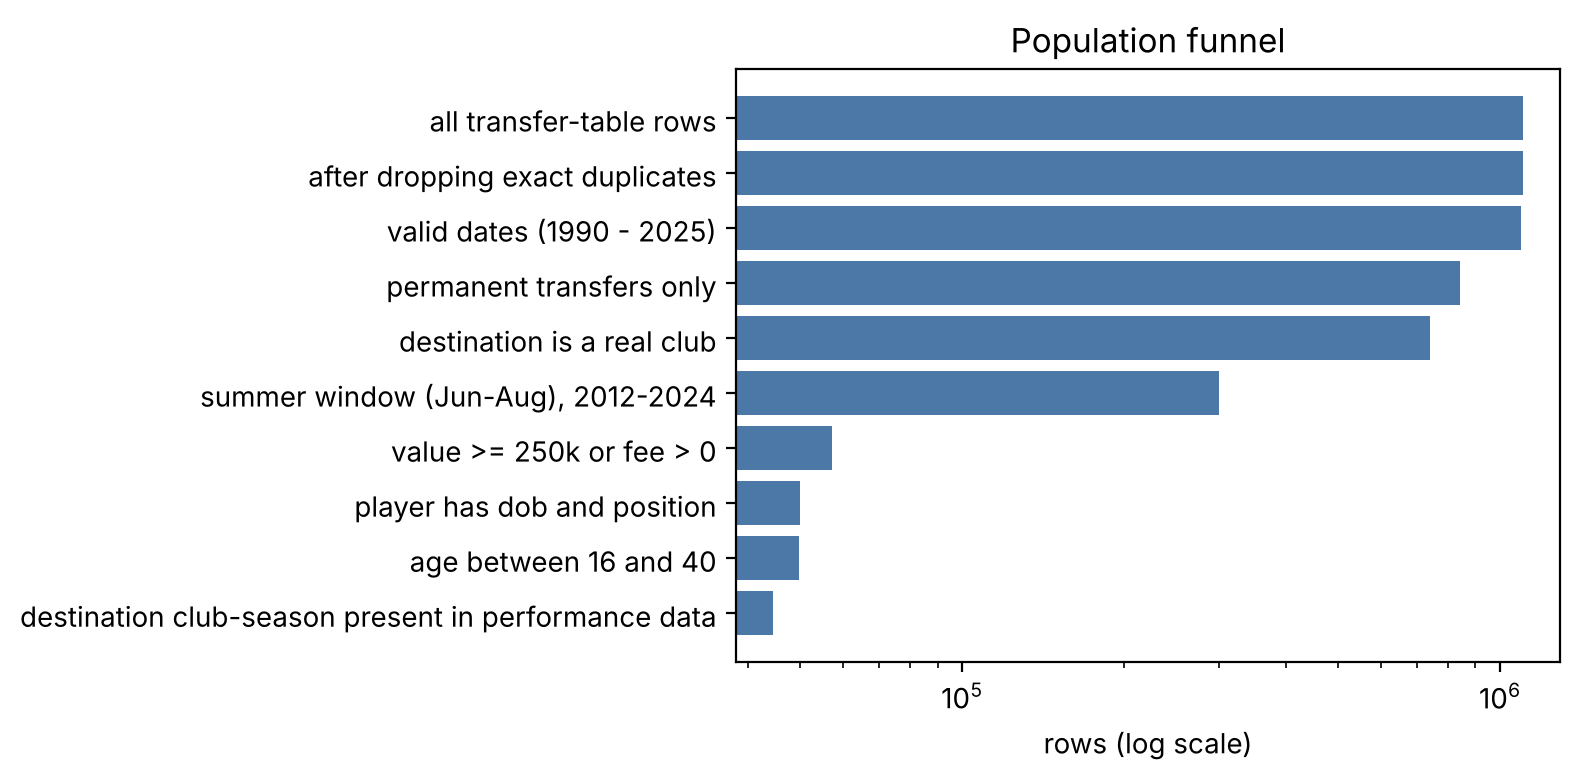

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(funnel_df["step"][::-1], funnel_df["rows"][::-1], color="#4c78a8")
ax.set_xscale("log"); ax.set_xlabel("rows (log scale)"); ax.set_title("Population funnel")
plt.tight_layout(); plt.show()

## 5 · Target definition

A **flop** = the player played **less than 25 % of his new club's main-competition matches** in the season that
starts right after the transfer (a zero-appearance season counts as a flop).

- *Why appearances share and not market value?* Playing time is what a club needs from a signing, it is observed
  directly, and it does not depend on a valuation published by a website.
- *Why 25 %?* A regular starter plays most matches; below a quarter of the matches the player is at best a
  rotation option. This threshold is a **choice** — notebook 03 tests 15 / 25 / 33 % to show the conclusions
  are not an artefact of it.
- Players with no row at all at the destination count as 0 appearances. The coverage filter above guarantees the
  club's season exists in the data, so a missing row means the player did not appear in the main competition.
  *(Residual risk: he may have played for the club's reserve team, which has a different club id.)*

We also store two **secondary outcomes** for robustness checks. They are *never* features:
`moved_on_12m` (sold or loaned out within 12 months) and `y_value_drop` (market value fell ≥ 30 % after a year).

In [9]:
FLOP_SHARE = 0.25

out = t[["tid", "player_id", "to_team_id", "season_y", "dest_matches"]].merge(
    pf_main[["player_id", "team_id", "season", "nb_on_pitch"]],
    left_on=["player_id", "to_team_id", "season_y"], right_on=["player_id", "team_id", "season"], how="left")
out["apps_after"]  = out["nb_on_pitch"].fillna(0)
out["share_after"] = (out["apps_after"] / out["dest_matches"]).clip(upper=1)
out["y_flop"]      = (out["share_after"] < FLOP_SHARE).astype(int)
t = t.merge(out[["tid", "apps_after", "share_after", "y_flop"]], on="tid", how="left")

# secondary outcome 1: left the new club within 12 months (any later transfer *from* the destination)
nxt = tr[["player_id", "transfer_date", "from_team_id"]].rename(
    columns={"transfer_date": "next_date", "from_team_id": "next_from"})
j = t[["tid", "player_id", "to_team_id", "transfer_date"]].merge(nxt, on="player_id")
j = j[(j["next_from"] == j["to_team_id"]) & (j["next_date"] > j["transfer_date"]) &
      (j["next_date"] <= j["transfer_date"] + pd.Timedelta(days=365))]
t["moved_on_12m"] = t["tid"].isin(j["tid"]).astype(int)

t[["apps_after", "share_after", "y_flop", "moved_on_12m"]].describe().round(3)

,apps_after,share_after,y_flop,moved_on_12m
count,44580.000,44580.000,44580.0,44580.000
mean,18.834,0.582,0.2,0.322
std,11.460,0.318,0.4,0.467
min,0.000,0.000,0.0,0.000
25%,10.000,0.333,0.0,0.000
50%,20.000,0.654,0.0,0.000
75%,28.000,0.857,0.0,1.000
max,46.000,1.000,1.0,1.000


In [10]:
print("overall flop rate:", round(t["y_flop"].mean(), 3))
print()
print(t.groupby("main_position")["y_flop"].agg(["mean", "size"]).round(3))
print()
print(t.groupby("season_y")["y_flop"].agg(["mean", "size"]).round(3))

overall flop rate: 0.2

                mean   size
main_position              
Attack         0.183  14097
Defender       0.192  14110
Goalkeeper     0.413   3308
Midfield       0.171  13065

           mean  size
season_y             
2012      0.212  2542
2013      0.240  2676
2014      0.222  2829
2015      0.213  3296
2016      0.212  3131
2017      0.197  3673
2018      0.226  3718
2019      0.201  3719
2020      0.185  2127
2021      0.176  3975
2022      0.183  4239
2023      0.176  4325
2024      0.180  4330


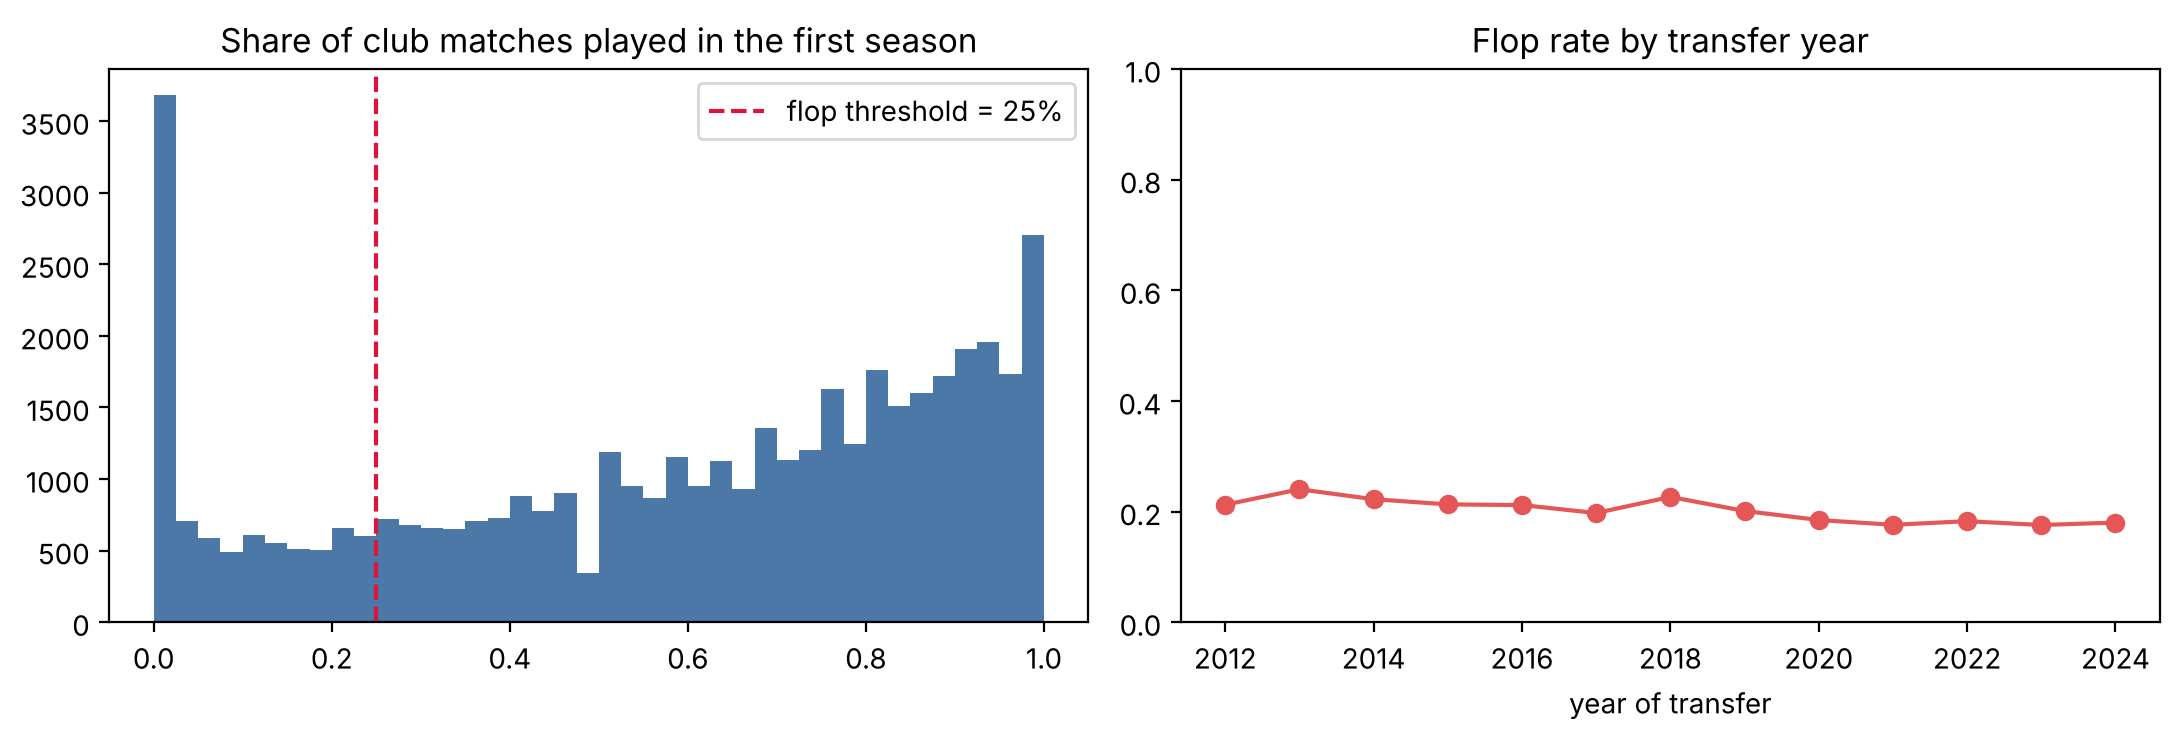

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(t["share_after"], bins=40, color="#4c78a8")
ax[0].axvline(FLOP_SHARE, color="crimson", ls="--", label=f"flop threshold = {FLOP_SHARE:.0%}")
ax[0].set_title("Share of club matches played in the first season"); ax[0].legend()
yr = t.groupby("season_y")["y_flop"].mean()
ax[1].plot(yr.index, yr.values, marker="o", color="#e45756"); ax[1].set_ylim(0, 1)
ax[1].set_title("Flop rate by transfer year"); ax[1].set_xlabel("year of transfer")
plt.tight_layout(); plt.show()

## 6 · Features — only what was knowable on the transfer date

Rule: **a feature may use data dated strictly before the transfer.**
For a transfer in summer `Y` the "outcome season" is `Y/Y+1`, so form features use seasons `Y-1` and `Y-2` only.
Section 6.6 proves the rule with assertions.

### 6.1 Player and deal basics

In [12]:
t["fee"]            = t["transfer_fee"].astype(float)
t["log_value"]      = np.log1p(t["value_at_transfer"])
t["log_fee"]        = np.log1p(t["fee"])
t["fee_zero"]       = (t["fee"] == 0).astype(int)                                   # free OR undisclosed (see audit)
t["fee_to_value"]   = (t["fee"] / t["value_at_transfer"]).where(t["value_at_transfer"] > 0).clip(upper=5)  # >1 = club pays above market value
t["from_no_club"]   = (t["from_team_name"] == "Without Club").astype(int)
t[["age", "log_value", "log_fee", "fee_zero", "fee_to_value"]].describe().round(2)

,age,log_value,log_fee,fee_zero,fee_to_value
count,44580.00,44580.00,44580.00,44580.00,43847.00
mean,26.25,13.24,4.12,0.71,0.34
std,4.18,2.03,6.45,0.46,0.81
min,16.00,0.00,0.00,0.00,0.00
25%,23.21,12.61,0.00,0.00,0.00
50%,26.12,13.12,0.00,1.00,0.00
75%,29.25,13.82,12.21,1.00,0.29
max,39.99,19.01,19.22,1.00,5.00


### 6.2 Previous-season form (seasons Y-1 and Y-2)

In [13]:
form_cols = ["share", "apps_all", "goals_pa", "assists_pa", "yellow_pa", "n_clubs"]
p1 = ps[["player_id", "season"] + form_cols].copy()
p1["season"] = p1["season"] + 1                                      # season Y-1 becomes the join key for Y
p1 = p1.rename(columns={c: f"prev1_{c}" for c in form_cols}).rename(columns={"season": "season_y"})

p2 = ps[["player_id", "season", "share", "apps_all"]].copy()
p2["season"] = p2["season"] + 2
p2 = p2.rename(columns={"share": "prev2_share", "apps_all": "prev2_apps_all", "season": "season_y"})

t = t.merge(p1, on=["player_id", "season_y"], how="left").merge(p2, on=["player_id", "season_y"], how="left")
t["prev1_missing"] = t["prev1_share"].isna().astype(int)
print("transfers with no previous-season record in a split-year league:", round(t["prev1_missing"].mean(), 3))

# career experience: first season we ever see the player in the performance table (any league format)
first_seen = pf.groupby("player_id")["season"].min().rename("first_season").reset_index()
t = t.merge(first_seen, on="player_id", how="left")
t["years_pro"] = (t["season_y"] - t["first_season"]).clip(lower=0)

# number of earlier permanent moves / loans (strictly earlier rows in the player's own history)
hist = tr.drop_duplicates().sort_values(["player_id", "transfer_date"]).copy()
hist["is_perm"] = (hist["transfer_type"] == "Transfer").astype(int)
hist["is_loan"] = (hist["transfer_type"] == "Loan").astype(int)
hist["n_prior_perm"] = hist.groupby("player_id")["is_perm"].cumsum() - hist["is_perm"]
hist["n_prior_loans"] = hist.groupby("player_id")["is_loan"].cumsum() - hist["is_loan"]
hist = hist.drop_duplicates(["player_id", "transfer_date", "from_team_id", "to_team_id"])
t = t.merge(hist[["player_id", "transfer_date", "from_team_id", "to_team_id", "n_prior_perm", "n_prior_loans"]],
            on=["player_id", "transfer_date", "from_team_id", "to_team_id"], how="left")
t[["prev1_share", "prev2_share", "years_pro", "n_prior_perm", "n_prior_loans"]].describe().round(2)

transfers with no previous-season record in a split-year league: 0.064


,prev1_share,prev2_share,years_pro,n_prior_perm,n_prior_loans
count,41717.00,40897.00,44579.00,44580.00,44580.00
mean,0.68,0.67,8.18,4.79,1.43
std,0.26,0.27,3.85,2.65,1.71
min,0.00,0.00,0.00,0.00,0.00
25%,0.50,0.49,5.00,3.00,0.00
50%,0.74,0.73,8.00,4.00,1.00
75%,0.89,0.89,11.00,6.00,2.00
max,1.00,1.00,24.00,23.00,14.00


### 6.3 Club context — destination and origin, previous season
League tier, final-table position and points per game of the **previous** season (`Y-1`).
We deliberately do not use season `Y` standings: they are not known on the transfer date.

In [14]:
lg = tcs[tcs["season_league_level_level_number"].notna()].copy()
lg = lg.drop_duplicates(["club_id", "season_id"])
n_teams = lg.groupby(["competition_id", "season_id"])["club_id"].transform("nunique")
lg["rank_pct"] = ((lg["season_rank"] - 1) / (n_teams - 1)).clip(0, 1)          # 0 = champion, 1 = last
lg["ppg"] = lg["season_points"] / lg["season_total_matches"]
lg = lg.rename(columns={"season_league_level_level_number": "level"})[["club_id", "season_id", "level", "rank_pct", "ppg"]]

def club_ctx(df, club_col, prefix):
    k = lg.copy(); k["season_id"] = k["season_id"] + 1                          # season Y-1 -> Y
    k = k.rename(columns={"club_id": club_col, "season_id": "season_y",
                          "level": f"{prefix}_level", "rank_pct": f"{prefix}_rank_pct", "ppg": f"{prefix}_ppg"})
    return df.merge(k, on=[club_col, "season_y"], how="left")

t = club_ctx(t, "to_team_id", "dest")
t = club_ctx(t, "from_team_id", "orig")
t["tier_change"] = t["orig_level"] - t["dest_level"]       # > 0: moving to a higher tier;  < 0: dropping down
print("share with destination context:", round(t["dest_level"].notna().mean(), 3),
      "| with origin context:", round(t["orig_level"].notna().mean(), 3))
t[["dest_level", "dest_rank_pct", "dest_ppg", "orig_level", "tier_change"]].describe().round(2)

share with destination context: 0.826 | with origin context: 0.791


,dest_level,dest_rank_pct,dest_ppg,orig_level,tier_change
count,36831.00,36804.00,36819.00,35273.00,31184.00
mean,1.66,0.44,1.46,1.59,-0.07
std,0.82,0.32,0.44,0.77,0.83
min,1.00,0.00,0.00,1.00,-4.00
25%,1.00,0.16,1.14,1.00,0.00
50%,1.00,0.42,1.39,1.00,0.00
75%,2.00,0.71,1.76,2.00,0.00
max,5.00,1.00,3.71,5.00,4.00


### 6.4 Competition for a place at the destination
How many players of the same position were *regular starters* (≥ 50 % of matches) for the destination club in
the previous season? The more regulars, the harder it is to break into the XI. It is a proxy: some of those
players may have left since.

In [15]:
reg = pf_main.merge(prof[["player_id", "main_position"]], on="player_id", how="left")
regulars = (reg[reg["share"] >= 0.5].groupby(["team_id", "season", "main_position"]).size()
               .rename("dest_regulars_same_pos").reset_index())
regulars["season"] += 1
regulars = regulars.rename(columns={"team_id": "to_team_id", "season": "season_y"})

squad = (pf_main.groupby(["team_id", "season"])["player_id"].nunique().rename("dest_squad_size_prev").reset_index())
squad["season"] += 1
squad = squad.rename(columns={"team_id": "to_team_id", "season": "season_y"})

t = t.merge(regulars, on=["to_team_id", "season_y", "main_position"], how="left") \
     .merge(squad, on=["to_team_id", "season_y"], how="left")
t["dest_regulars_same_pos"] = t["dest_regulars_same_pos"].fillna(0)      # club had data but no regular at this position
t[["dest_regulars_same_pos", "dest_squad_size_prev"]].describe().round(2)

,dest_regulars_same_pos,dest_squad_size_prev
count,44580.00,43135.00
mean,3.25,24.49
std,1.87,9.88
min,0.00,1.00
25%,2.00,18.00
50%,3.00,26.00
75%,5.00,31.00
max,11.00,57.00


### 6.5 Market-value trajectory and injury history (the leakage-prone part)

- **Market value:** value one year before the transfer and the player's peak value so far
  (`merge_asof` looks *backwards* only).
- **Injuries:** the injury table was scraped in 2026 and lists every injury ever. We keep only injuries that
  **started before the transfer date** and count only the days **up to the transfer date** — an injury that began
  before and ended after the move would otherwise leak the future.

In [16]:
mv["date"] = pd.to_datetime(mv["date_unix"], errors="coerce")
mv = mv.dropna(subset=["date"]).sort_values("date")
mv["date"] = mv["date"].astype("datetime64[ns]")      # one datetime resolution for merge_asof (pandas 2 vs 3)
mv["peak_so_far"] = mv.groupby("player_id")["value"].cummax()

base = t[["tid", "player_id", "transfer_date", "value_at_transfer"]].copy()
base["transfer_date"] = base["transfer_date"].astype("datetime64[ns]")

# value ~12 months before (latest valuation at least 365 days old, not older than +240 days beyond that)
a = base.assign(key_date=base["transfer_date"] - pd.Timedelta(days=365)).sort_values("key_date")
a = pd.merge_asof(a, mv[["player_id", "date", "value"]].rename(columns={"date": "mv12_date", "value": "mv_12m_ago"}),
                  left_on="key_date", right_on="mv12_date", by="player_id",
                  direction="backward", tolerance=pd.Timedelta(days=240))

# peak value on or before the transfer date
b = base.sort_values("transfer_date")
b = pd.merge_asof(b, mv[["player_id", "date", "peak_so_far"]].rename(columns={"date": "mvpeak_date"}),
                  left_on="transfer_date", right_on="mvpeak_date", by="player_id", direction="backward")

# secondary outcome (NOT a feature): value ~12 months AFTER the transfer
c = base.assign(key_date=base["transfer_date"] + pd.Timedelta(days=365)).sort_values("key_date")
c = pd.merge_asof(c, mv[["player_id", "date", "value"]].rename(columns={"date": "mv_after_date", "value": "mv_after"}),
                  left_on="key_date", right_on="mv_after_date", by="player_id",
                  direction="nearest", tolerance=pd.Timedelta(days=120))

t = (t.merge(a[["tid", "mv12_date", "mv_12m_ago"]], on="tid", how="left")
      .merge(b[["tid", "mvpeak_date", "peak_so_far"]], on="tid", how="left")
      .merge(c[["tid", "mv_after"]], on="tid", how="left"))

t["value_change_12m"] = np.log1p(t["value_at_transfer"]) - np.log1p(t["mv_12m_ago"])   # + = value rising before the move
t["value_to_peak"]    = (t["value_at_transfer"] / t["peak_so_far"]).where(t["peak_so_far"] > 0).clip(upper=1.5)
t["y_value_drop"] = np.where(t["mv_after"].notna() & (t["value_at_transfer"] > 0),
                             (t["mv_after"] / t["value_at_transfer"] <= 0.7).astype(float), np.nan)
print("value history available (12m ago):", round(t["mv_12m_ago"].notna().mean(), 3),
      "| value-drop outcome available:", round(t["y_value_drop"].notna().mean(), 3))

value history available (12m ago): 0.837 | value-drop outcome available: 0.893


In [17]:
inj["from_date"] = pd.to_datetime(inj["from_date"], errors="coerce")
inj["end_date"]  = pd.to_datetime(inj["end_date"],  errors="coerce")
inj = inj.dropna(subset=["from_date"])
inj["end_date"] = inj["end_date"].fillna(inj["from_date"])

x = t[["tid", "player_id", "transfer_date"]].merge(inj[["player_id", "from_date", "end_date"]], on="player_id")
x = x[x["from_date"] < x["transfer_date"]].copy()                       # only injuries that STARTED before the move
x["days_before"] = (x["transfer_date"] - x["from_date"]).dt.days
# days missed counted only up to the transfer date (clip the end of the injury)
x["eff_days"] = ((x[["end_date", "transfer_date"]].min(axis=1) - x["from_date"]).dt.days + 1).clip(lower=0)

def agg_window(days, suffix):
    w = x[x["days_before"] <= days]
    return (w.groupby("tid").agg(**{f"inj_days_{suffix}": ("eff_days", "sum"),
                                    f"inj_n_{suffix}": ("eff_days", "size")}).reset_index())

inj365, inj730 = agg_window(365, "1y"), agg_window(730, "2y")
long_inj = (x[(x["days_before"] <= 730) & (x["eff_days"] >= 60)].groupby("tid").size().rename("inj_long_2y").reset_index())

for part in (inj365, inj730, long_inj):
    t = t.merge(part, on="tid", how="left")
inj_cols = ["inj_days_1y", "inj_n_1y", "inj_days_2y", "inj_n_2y", "inj_long_2y"]
t[inj_cols] = t[inj_cols].fillna(0)      # no injury record = no injury listed (injury coverage is itself uneven, see section 8)
t[inj_cols].describe().round(2)

,inj_days_1y,inj_n_1y,inj_days_2y,inj_n_2y,inj_long_2y
count,44580.00,44580.00,44580.00,44580.00,44580.00
mean,12.91,0.42,28.89,0.82,0.13
std,33.82,0.88,61.11,1.45,0.38
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00,0.00
75%,4.00,1.00,31.00,1.00,0.00
max,599.00,11.00,845.00,15.00,4.00


### 6.6 Leakage guards
These assertions fail loudly if any feature uses information from on or after the transfer date.
They are the evidence for the "no leakage from the future" requirement.

In [18]:
# 1) form features come from the season immediately before the transfer year (Y-1), never from Y or later
chk = t[["tid", "player_id", "season_y", "prev1_share"]].dropna().copy()
chk["season_prev"] = chk["season_y"] - 1
chk = chk.merge(ps[["player_id", "season", "share"]], left_on=["player_id", "season_prev"],
                right_on=["player_id", "season"], how="left")
assert chk["share"].notna().all() and np.allclose(chk["prev1_share"], chk["share"]), "prev1 does not come from season Y-1"
assert (chk["season"] < chk["season_y"]).all()

# 2) market-value features use valuations dated before the transfer
assert (t["mv12_date"].dropna() <= t.loc[t["mv12_date"].notna(), "transfer_date"] - pd.Timedelta(days=365)).all()
assert (t["mvpeak_date"].dropna() <= t.loc[t["mvpeak_date"].notna(), "transfer_date"]).all()

# 3) injuries: every counted injury began before the transfer, and no more days than elapsed are counted
assert (x["from_date"] < x["transfer_date"]).all()
assert (x["eff_days"] <= x["days_before"] + 1).all()

# 4) outcome columns are disjoint from feature columns (defined in section 7)
print("all leakage checks passed")

all leakage checks passed


## 7 · Final table, sanity checks, save

In [19]:
ID_COLS = ["tid", "player_id", "player_name", "transfer_date", "season_y", "from_team_id", "from_team_name",
           "to_team_id", "to_team_name"]

FEATURES = [
    # player
    "age", "height", "foot", "main_position", "role", "years_pro", "n_prior_perm", "n_prior_loans",
    # deal
    "log_value", "log_fee", "fee_zero", "fee_to_value", "from_no_club",
    # value trajectory
    "value_change_12m", "value_to_peak",
    # previous-season form
    "prev1_share", "prev1_apps_all", "prev1_goals_pa", "prev1_assists_pa", "prev1_yellow_pa", "prev1_n_clubs",
    "prev2_share", "prev2_apps_all", "prev1_missing",
    # clubs
    "dest_level", "dest_rank_pct", "dest_ppg", "orig_level", "orig_rank_pct", "orig_ppg", "tier_change",
    "dest_regulars_same_pos", "dest_squad_size_prev",
    # injuries
    "inj_days_1y", "inj_n_1y", "inj_days_2y", "inj_n_2y", "inj_long_2y",
]
OUTCOMES = ["apps_after", "share_after", "y_flop", "moved_on_12m", "y_value_drop"]

assert not set(FEATURES) & set(OUTCOMES), "leakage: an outcome is listed as a feature"
final = t[ID_COLS + FEATURES + OUTCOMES].copy()
final["transfer_date"] = final["transfer_date"].dt.strftime("%Y-%m-%d")

assert final["tid"].is_unique
assert final["y_flop"].isin([0, 1]).all()
assert final["age"].between(16, 40).all()
print(final.shape)

(44580, 52)


In [20]:
# missing values per feature
miss = final[FEATURES].isna().mean().sort_values(ascending=False)
miss[miss > 0].round(3).to_frame("share_missing")

,share_missing
tier_change,0.300
orig_ppg,0.209
orig_rank_pct,0.209
orig_level,0.209
dest_rank_pct,0.174
dest_ppg,0.174
dest_level,0.174
value_change_12m,0.163
prev2_share,0.083
prev2_apps_all,0.079


In [21]:
# quick sanity: do the features point in a sensible direction?  (no modelling yet - that is notebook 03)
chk = final.copy()
chk["age_group"] = pd.cut(chk["age"], [15, 21, 24, 28, 32, 41])
print(chk.groupby("age_group", observed=True)["y_flop"].agg(["mean", "size"]).round(3), "\n")
chk["prev1_bin"] = pd.cut(chk["prev1_share"], [-0.01, 0.25, 0.5, 0.75, 1.0])
print(chk.groupby("prev1_bin", observed=True)["y_flop"].agg(["mean", "size"]).round(3), "\n")
print("flop rate when previous season missing:", round(chk.loc[chk["prev1_missing"] == 1, "y_flop"].mean(), 3),
      "| present:", round(chk.loc[chk["prev1_missing"] == 0, "y_flop"].mean(), 3))

            mean   size
age_group              
(15, 21]   0.415   4645
(21, 24]   0.234   9479
(24, 28]   0.155  15230
(28, 32]   0.150  10961
(32, 41]   0.176   4265 

                mean   size
prev1_bin                  
(-0.01, 0.25]  0.290   3590
(0.25, 0.5]    0.226   7107
(0.5, 0.75]    0.192  11090
(0.75, 1.0]    0.166  19930 

flop rate when previous season missing: 0.283 | present: 0.194


In [22]:
out_path = f"{PROC_DIR}/transfers_model.csv.gz"
final.to_csv(out_path, index=False, compression="gzip")

dictionary = pd.DataFrame({
    "column": ID_COLS + FEATURES + OUTCOMES,
    "role": ["id"] * len(ID_COLS) + ["feature"] * len(FEATURES) + ["outcome"] * len(OUTCOMES),
})
dictionary.to_csv(f"{PROC_DIR}/columns.csv", index=False)
funnel_df.to_csv(f"{PROC_DIR}/population_funnel.csv", index=False)
print(f"saved {out_path}: {os.path.getsize(out_path) / 1e6:.1f} MB, {final.shape[0]:,} rows x {final.shape[1]} cols")

saved ../data/processed/transfers_model.csv.gz: 4.4 MB, 44,580 rows x 52 cols


## 8 · Limitations and pitfalls found so far

These feed directly into the "typical football-analytics traps" part of the project.

| # | Pitfall | What we saw | What we did |
|---|---|---|---|
| 1 | **Data leakage** | Injury table lists all injuries up to 2026; market values keep updating after a move | Only records dated before the transfer; injury days clipped at the transfer date; `merge_asof` looks backwards only; assertions in 6.6 |
| 2 | **Playing time is unstable / missing** | `minutes_played` missing in ~62 % of rows in every season | Use appearances as share of club matches, not minutes; sub appearances count as full ones, so the label is a little generous to bench players |
| 3 | **Different leagues** | Calendar-year leagues (MLS, Brazil, Nordics) have no "summer" transfer in our sense; league strength differs | Restricted to split-year seasons; added tier, final-table position and points-per-game context for both clubs |
| 4 | **Different positions** | Goalkeepers play all or none of the matches, outfield players rotate | Position kept as feature; notebook 02/03 report results per position |
| 5 | **Sample selection bias** | Only completed transfers exist, not the ones clubs rejected; only deals with a valuation or fee are kept; only clubs present in the performance data | Documented; conclusions apply to the observed market, not to all possible signings |
| 6 | **Fee ambiguity** | `fee = 0` mixes free transfers and undisclosed fees | Raw flag `fee_zero` kept, fee features interpreted with caution |
| 7 | **Correlation ≠ causation** | A feature predicting flops (e.g. many regulars at the position) does not mean it *causes* them | Wording of conclusions; no causal claims |
| 9 | **Zero-appearance spike** | ~8 % of transfers have exactly 0 appearances in the first season (spike at 0 in the histogram in section 5); some of these players may have played only for the club's reserve team, which has a different club id | Counted as flops (the club did not use him in its main competition); check in notebook 03 that results hold when these rows are excluded |
| 8 | **Injury coverage is uneven** | Minor leagues have sparser injury records; "no record" is coded as 0 | Documented; check robustness in notebook 03 |

**Next:** `02_eda.ipynb` — exploratory analysis and hypotheses; `03_model_evaluation.ipynb` — baselines vs model with a time-based split.